## Introduction to Quantum Computing: Labs

### Lab 9: Expectation Values

In this lab, we will study the expectation values of observables. Expectation values describe the average measurement value we would obtain if we prepared the same quantum state many times and always measured the same observable.

This is particularly useful in quantum computing because many algorithms consider not only individual measurement outcomes but also evaluate weighted sums of measurement values.


### Understanding Expectation Values

An observable describes a measurable quantity and is represented by a Hermitian operator $O$. Its eigenvalues are the possible measurement values. For a normalized quantum state $|\psi\rangle$, the expectation value is defined as

$$
\langle O \rangle = \langle \psi | O | \psi \rangle .
$$

When measuring the Pauli-$Z$ operator, we distinguish between the output **bit** and the corresponding **measurement value**:

- Bit `0` corresponds to the measurement value $+1$.
- Bit `1` corresponds to the measurement value $-1$.

With the probabilities $p_0$ and $p_1$, we therefore obtain

$$
\langle Z \rangle = (+1)\,p_0 + (-1)\,p_1 = p_0 - p_1.
$$

The expectation value describes the average over many repetitions. It does not have to be a possible value of an individual measurement: for example, it is 0 when $p_0=p_1=1/2$.

In Qiskit, we describe observables using the class `SparsePauliOp`. For example, a single Pauli-$Z$ operator is defined as follows:

```python
observable = SparsePauliOp("Z")
```

In the following example, we calculate the expectation value $\langle Z \rangle$ for a circuit with an $R_x$ rotation. We use the helper function `qiskit_expectation_value` for this. The function `sv_probs` gives us the ideal probabilities from the statevector; when called without a number of shots, `qiskit_expectation_value` calculates the ideal expectation value here. With a finite number of actual measurements, we would estimate these quantities from relative frequencies and observe statistical fluctuations.

### Qubit Numbering and the Qiskit Convention

In this notebook, we number the qubits **starting at 1, from left to right**. In a state $|b_1b_2\ldots b_n\rangle$, the leftmost bit belongs to qubit 1, the next bit to qubit 2, and so on. The helper function `sv_probs` also displays the probabilities in this order. In formulas, we write the operators accordingly: $Z_1 I_2 X_3 = Z \otimes I \otimes X$.

In the Qiskit code, we need to keep two details in mind:

- **Python indices start at 0.** Our qubit 1 has index `0` in the code, qubit 2 has index `1`, and so on. For example, `qc.h(0)` acts on our qubit 1. Qiskit circuit drawings also use these Python indices starting at 0.
- **For `SparsePauliOp`, we use the Qiskit convention.** The rightmost character acts on our qubit 1 (Python index `0`), the next character from the right acts on qubit 2, and so on. A Pauli string therefore uses the reverse order compared with our formulas and the bitstrings from `sv_probs`.

Example for three qubits:

$$
Z_1 I_2 X_3
\quad\longleftrightarrow\quad
Z \otimes I \otimes X
\quad\longleftrightarrow\quad
\texttt{SparsePauliOp("XIZ")}.
$$

The indices in all the following formulas and the qubit numbers in the explanations refer to our numbering starting at 1.


In [46]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qc_lecture_tools.expectation_value import qiskit_expectation_value
from qc_lecture_tools.statevector import sv_probs

# Define a circuit with an R_x rotation
qc_example = QuantumCircuit(1)
qc_example.rx(np.pi / 3, 0)

# Examine the probabilities
display(sv_probs(qc_example))

# Define the observable: Z on qubit 1 (Python index 0)
observable = SparsePauliOp("Z")

# Calculate the theoretical expectation value
exp_val = qiskit_expectation_value(qc_example, observable)
print(f"Expectation value <Z>: {exp_val:.4f}")


<IPython.core.display.Math object>

Expectation value <Z>: 0.5000


### Exercise 1: Basic Expectation Values

**Exercise 1.1:** Start with a single qubit. Create one circuit for the state $|0\rangle$ and another for the state $|1\rangle$. Calculate the expectation value of the Pauli-$Z$ operator for both states.

In [47]:
# TODO Exercise 1.1


**Exercise 1.2:** Apply a Hadamard gate $H$ to a single qubit to create the superposition state

$$
|+\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

Calculate the expectation value $\langle Z \rangle$. What does the result tell you about the possible measurement outcomes of this state?


In [48]:
# TODO Exercise 1.2


**Exercise 1.3:** Use the rotation gate $R_y(\theta)$ to prepare different states. Calculate $\langle Z \rangle$ for different angles $\theta \in [0, 2\pi]$.

How does the expectation value change as you rotate the qubit?

Optionally, visualize the result using `matplotlib` and compare it with the function $\cos(\theta)$.


In [49]:
# TODO Exercise 1.3


### Exercise 2: Expectation Values for Multiple Qubits

For multiple qubits, we can calculate expectation values of observables consisting of several Pauli operators, for example $Z_1 Z_2 Z_4$.

To represent these operators compactly, we use **Pauli strings**. A Pauli string has exactly as many characters as there are qubits in the circuit:

- `"Z"` means that a $Z$ operator acts on this qubit.
- `"I"` means that the identity acts on this qubit, so this qubit does not contribute a sign.

We first write Pauli strings in our order, **from qubit 1 on the left to qubit $n$ on the right**. When passing them to `SparsePauliOp`, we reverse this order to follow the Qiskit convention: there, the **rightmost** character acts on our qubit 1. For two qubits, `SparsePauliOp("IZ")` therefore describes $Z_1$, and `SparsePauliOp("ZI")` describes the operator $Z_2$. For `"ZZ"`, reversing the order makes no difference because the same operator acts on both qubits.

Example for 5 qubits: we count positions 1, 2, 3, 4, 5 from the left. The identities on qubits 3 and 5 are included in the Pauli string:

$$
Z_1 Z_2 Z_4
\quad \longrightarrow \quad
\texttt{"ZZIZI"}
\quad \longrightarrow \quad
\text{for SparsePauliOp: } \texttt{"IZIZZ"} .
$$

The contribution of a bitstring is determined by the signs of the individual $Z$ operators. For $Z$, bit `0` gives a factor of $+1$, and bit `1` gives a factor of $-1$. Identities always give a factor of $+1$.

Example:

$$
\langle 101 | Z_1 Z_2 I_3 | 101 \rangle
= \langle 1 | Z_1 | 1 \rangle \cdot \langle 0 | Z_2 | 0 \rangle \cdot \langle 1 | I_3 | 1 \rangle
= (-1) \cdot (+1) \cdot (+1) = -1 .
$$

For each individual bitstring $i$, we therefore determine:

1. the factor $\alpha_i = \pm 1$,
2. the contribution to the expectation value $p_i \cdot \alpha_i$.

The expectation value is then the sum of all contributions $p_i \cdot \alpha_i$.


**Exercise 2.1:** Use the function `sv_probs` to determine the probabilities of the given state. Then calculate the expectation value

$$
\langle \Psi | Z_1 Z_2 | \Psi \rangle
$$

by hand, determining the sign for each of the four bitstrings. Afterwards, check your result using `qiskit_expectation_value`.


In [50]:
# Given circuit for Exercise 2.1
quantum_circuit = QuantumCircuit(2)
quantum_circuit.rx(np.pi / 3, 0)
quantum_circuit.cx(0, 1)
quantum_circuit.rx(np.pi / 3, 0)


In [51]:
# TODO Exercise 2.1


**Exercise 2.2:** Consider the following quantum state. How would you calculate the expectation value

$$
\langle \Psi | Z_1 Z_2 Z_3 | \Psi \rangle
$$

for this state? Again, determine the probabilities using `sv_probs`, calculate the expectation value by hand, and then check the result using `qiskit_expectation_value`.


In [52]:
# Given circuit for Exercise 2.2
quantum_circuit = QuantumCircuit(3)
quantum_circuit.rx(np.pi / 3, 0)
quantum_circuit.cx(0, 1)
quantum_circuit.rx(np.pi / 2, 1)
quantum_circuit.cx(1, 2)
quantum_circuit.rx(np.pi / 3, 2)


In [53]:
# TODO Exercise 2.2


**Exercise 2.3:** Repeat Exercise 2.2 for the expectation value

$$
\langle \Psi | Z_1 I_2 Z_3 | \Psi \rangle .
$$

Here, the identity operator $I$ must be taken into account when determining the signs: it never changes the sign.


In [54]:
# TODO Exercise 2.3


### Exercise 3: Expectation Values of the Pauli Operators $X$ and $Y$

So far, we have considered expectation values of $Z$ operators. This is particularly simple because $Z$ does not swap the basis states:

$$
Z |0\rangle = (+1)|0\rangle
\qquad \text{and} \qquad
Z |1\rangle = (-1)|1\rangle .
$$

The $X$ operator behaves differently. For a general state

$$
|\Psi\rangle = \alpha |0\rangle + \beta |1\rangle
$$

we obtain

$$
\langle \Psi | X | \Psi \rangle
= (\overline{\alpha}\langle 0| + \overline{\beta}\langle 1|)
X(\alpha |0\rangle + \beta |1\rangle)
= \overline{\alpha}\beta + \overline{\beta}\alpha .
$$

This value cannot be determined from the probabilities of the basis states in the original $Z$ basis alone; the relative phase between the amplitudes also matters. However, we can change the measurement basis and then use a $Z$ measurement again:

- For the $X$ operator, the general relation is $X = H Z H$.
- For the $Y$ operator, the general relation is $Y = S H Z H S^\dagger$.

In practice, this means:

- For an $X$ measurement, we append `h()` to the corresponding qubit before evaluating the probabilities.
- For a $Y$ measurement, we append `sdg()` followed by `h()` to the corresponding qubit.

We can then evaluate the probabilities in the Z basis as before.

**Exercise 3.1:** A single-qubit state is given. Determine the expectation value of the $X$ operator by appending a Hadamard gate at the correct position, determining the probabilities, and calculating the expectation value from them.

Check the result using `qiskit_expectation_value` and `SparsePauliOp("X")` for the original circuit.


In [55]:
# Given circuit for Exercise 3.1
quantum_circuit = QuantumCircuit(1)
quantum_circuit.ry(np.pi / 2, 0)
quantum_circuit.rz(np.pi / 3, 0)


In [56]:
# TODO Exercise 3.1


**Exercise 3.2:** Work out how to determine the expectation value of the $Y$ operator. Follow the same approach as in Exercise 3.1. The gate $S^\dagger$ is available in Qiskit as `sdg()`.


In [57]:
# TODO Exercise 3.2


**Exercise 3.3:** Work out how to adapt the circuit for multiple Pauli operators.

The given observable has $X$ on qubit 1, $Y$ on qubit 2, and $Z$ on qubit 3, i.e. $X_1Y_2Z_3$. Adapt the circuit and determine the expectation value of the operator $Z_1Z_2Z_3$ after the basis change. Use `qiskit_expectation_value` with the observable `"ZZZ"` instead of calculating the expectation value by hand.

Again, check your result using the original circuit and the appropriate Qiskit observable `SparsePauliOp(...)`. Pay attention to the order of the characters in the Pauli string.


In [58]:
# Given circuit for Exercise 3.3
quantum_circuit = QuantumCircuit(3)
quantum_circuit.ry(np.pi / 3, 0)
quantum_circuit.h(1)  # Prepare qubit 2 in superposition
quantum_circuit.rz(np.pi / 7, 1)
quantum_circuit.ry(np.pi / 4, 2)


In [59]:
# TODO Exercise 3.3


### Exercise 4: Combining Multiple Observables

In quantum computing, we are often interested in a sum of different expectation values. Mathematically, this corresponds, for example, to the expectation value of a Hamiltonian:

$$
\langle H \rangle = \sum_i w_i \langle O_i \rangle .
$$

In Qiskit, we can add `SparsePauliOp` objects directly:

```python
obs = 0.5 * SparsePauliOp("IZ") + 0.5 * SparsePauliOp("ZI")
```

**Exercise 4.1:** Create a 2-qubit circuit in which you apply $R_y(\pi/4)$ to qubit 1 and $R_y(\pi/3)$ to qubit 2.

Keep the Qiskit convention for `SparsePauliOp` in mind: the rightmost character acts on our qubit 1, and the leftmost character on qubit 2. Therefore, `"IZ"` describes the operator $Z_1 = Z \otimes I$ in our notation, and `"ZI"` describes the operator $Z_2 = I \otimes Z$. In the circuit, use Python index `0` for qubit 1 and Python index `1` for qubit 2.

1. Calculate the expectation value $\langle Z_1 \rangle$ using `SparsePauliOp("IZ")`.
2. Calculate the expectation value $\langle Z_2 \rangle$ using `SparsePauliOp("ZI")`.
3. Calculate the expectation value of the combined operator
   $$O = 0.5 Z_1 + 0.5 Z_2 = 0.5 \cdot (Z \otimes I) + 0.5 \cdot (I \otimes Z).$$
4. Check that the combined result is the average of the two individual results.


In [60]:
# TODO Exercise 4.1


**Exercise 4.2:** We will now consider an observable consisting of two different Pauli terms:

```python
obs = 0.5 * SparsePauliOp("ZZ") + 0.5 * SparsePauliOp("XY")
```

How can this sum be calculated?

Use `sv_probs` and adapted circuits to calculate the expectation value of each term, and add the weighted results. Afterwards, check the result using the full observable and `qiskit_expectation_value`.

Note on the Qiskit convention: in `SparsePauliOp("XY")`, `Y` acts on our qubit 1, and `X` acts on qubit 2. In our order from left to right, this is the operator $Y_1 X_2 = Y \otimes X$.


In [61]:
# Given circuit for Exercise 4.2
qc_4_2 = QuantumCircuit(2)
qc_4_2.ry(np.pi / 3, 0)
qc_4_2.rz(np.pi / 4, 0)
qc_4_2.cx(0, 1)


In [62]:
# TODO Exercise 4.2


**Exercise 4.3:** We can often group several terms of an observable and reuse the same probabilities. This is particularly important when obtaining the probabilities through measurements on a real quantum computer requires considerable effort.

The following observable on four qubits is given. The strings in `SparsePauliOp` use Qiskit order, i.e. from left to right for **qubits 4, 3, 2, 1**. For example, `"XIXY"` describes the operator $Y_1 X_2 I_3 X_4$ in our notation:

```python
observable = (
    SparsePauliOp("ZZZZ")
    + SparsePauliOp("ZIIZ")
    + SparsePauliOp("XIXY")
    + SparsePauliOp("IZXI")
    + SparsePauliOp("IXXY")
    + SparsePauliOp("YXXY")
)
```

Consider the following questions:

1. Which terms can you evaluate directly in the $Z$ basis?
2. Which other terms can use the same basis changes and therefore the same measurement data?

A grouping with a brief explanation is sufficient.

Hint: the identity operator $I$ can be ignored when changing the basis. It always contributes a factor of $+1$ to the sign.

Check your grouping using:

```python
observable.group_commuting(qubit_wise=True)
```


In [63]:
# Given observable for Exercise 4.3
observable = (
    SparsePauliOp("ZZZZ")
    + SparsePauliOp("ZIIZ")
    + SparsePauliOp("XIXY")
    + SparsePauliOp("IZXI")
    + SparsePauliOp("IXXY")
    + SparsePauliOp("YXXY")
)

# TODO Exercise 4.3
# Group the terms, explain your choice, and check the grouping.


### Bonus Exercise: Expectation Values with Simulated Quantum Hardware

So far, we have calculated ideal expectation values using the statevector. Now determine the expectation value using the **simulated hardware backend `FakeManilaV2`** from Lab 8. The circuit runs locally with a noise model of the device. Afterwards, you can replace the fake backend with real IBM quantum hardware yourself.

We use the two-qubit circuit from Exercise 2.1 and the observable

$$
O=Z_1Z_2.
$$

The ideal reference value is calculated in the following provided code.


In [64]:
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

backend = FakeManilaV2()
# You can replace this with a real backend if you have access to IBM Quantum.
# On real IBM hardware, test with a few repetitions first: each repetition starts a job.
print("Selected backend:", backend.name)

# Given circuit and observable

quantum_circuit = QuantumCircuit(2)
quantum_circuit.rx(np.pi / 3, 0)  # Qubit 1
quantum_circuit.cx(0, 1)         # Qubit 1 controls qubit 2
quantum_circuit.rx(np.pi / 3, 0)
observable = SparsePauliOp("ZZ")

# Ideal reference value from the statevector
ideal_value = float(qiskit_expectation_value(quantum_circuit, observable))
print(f"Ideal expectation value <Z_1 Z_2>: {ideal_value:.4f}")


Selected backend: fake_manila
Ideal expectation value <Z_1 Z_2>: 0.5000


**Bonus Exercise 1: Transpiling the Circuit and Examining the Observable**

Transpile the circuit for `backend`. Adapt the observable using `apply_layout` and compare the Pauli strings before and after the adjustment. Why are `I` operators added, and where are the two `Z` operators located relative to the qubits of the transpiled circuit?

**Hint:**

Transpiling:
```python
from qiskit.compiler import transpile

qc_transpiled = transpile(quantum_circuit, backend=backend)
```

Adapting the observable:
```python
observable_mapped = observable.apply_layout(qc_transpiled.layout)
```


In [65]:
# TODO Bonus Exercise 1
# Create qc_transpiled and observable_mapped.
# Print the observable before and after apply_layout and examine the circuit.


**Bonus Exercise 2: Calculating the Expectation Value with `EstimatorV2`**

The Estimator handles the measurements and the calculation of the expectation value. We pass it the already transpiled circuit and the observable adapted using `apply_layout`. We read the expectation value estimate from `result[0].data.evs`.

With `default_precision = 1 / np.sqrt(num_shots)`, we set the desired precision. Larger values of `num_shots` request a more precise estimate. Here, the parameter is converted into a target precision; the actual number of shots used also depends on the Estimator settings.

Examine the result and run the following cell several times. How do the estimates differ from one another and from the ideal reference value?


In [66]:
# Provided code for Bonus Exercise 2
from qiskit_ibm_runtime import EstimatorV2

num_shots = 1000

estimator = EstimatorV2(
    mode=backend, options={"default_precision": 1 / np.sqrt(num_shots)}
)

# TODO Uncomment the following lines
#job = estimator.run([(qc_transpiled, observable_mapped)])
#result = job.result()
#print("Estimated expectation value:", float(result[0].data.evs))


**Bonus Exercise 3: Plotting a Histogram**

The following code repeats the estimation 300 times and stores the resulting expectation values. It then calculates their mean. Compare this with the ideal reference value `ideal_value` from the provided code.

A histogram is then plotted from the estimates. How does its width change when you increase the desired precision by choosing a larger `num_shots`? Distinguish between the measurements per estimate and the number of repetitions `num_repetitions_bonus`.


In [67]:
# Provided code for Bonus Exercise 3: repeated expectation value estimates
num_shots = 1000
num_repetitions = 300
expectation_values = []

estimator = EstimatorV2(
    mode=backend, options={"default_precision": 1 / np.sqrt(num_shots)}
)

#for repetition in range(num_repetitions):
    #job = estimator.run([(qc_transpiled, observable_mapped)])
    #result = job.result()
    #value = float(result[0].data.evs)
    #expectation_values.append(value)

expectation_values = np.asarray(expectation_values)
print(f"Mean of the estimates: {expectation_values.mean():.4f}")


Mean of the estimates: nan


/var/folders/sv/lv0fk6gj2hn5b0gsg27ymc640000gp/T/ipykernel_71785/3121932091.py:17: RuntimeWarning: Mean of empty slice
  print(f"Mean of the estimates: {expectation_values.mean():.4f}")


/var/folders/sv/lv0fk6gj2hn5b0gsg27ymc640000gp/T/ipykernel_71785/3147566102.py:14: RuntimeWarning: Mean of empty slice
  expectation_values.mean(),


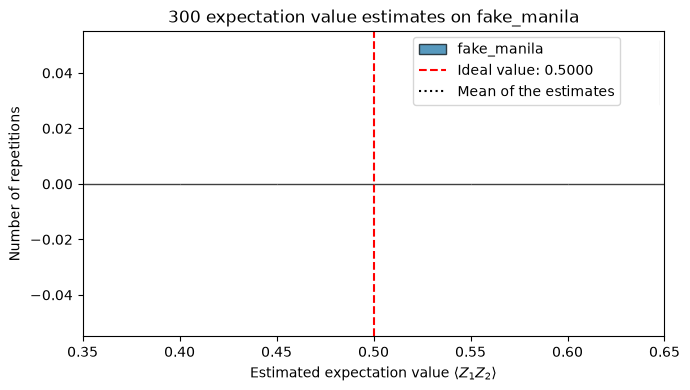

In [68]:
# Code for the histogram of expectation value estimates

plt.figure(figsize=(7, 4))
plt.hist(
    expectation_values,
    bins=20,
    edgecolor="black",
    alpha=0.75,
    label=backend.name,
)
plt.axvline(ideal_value, color="red", linestyle="--",
            label=f"Ideal value: {ideal_value:.4f}")
plt.axvline(
    expectation_values.mean(),
    color="black",
    linestyle=":",
    label="Mean of the estimates",
)
plt.xlabel(r"Estimated expectation value $\langle Z_1 Z_2 \rangle$")
plt.ylabel("Number of repetitions")
plt.title(f"{num_repetitions} expectation value estimates on {backend.name}")
plt.legend()
plt.xlim([0.35,0.65])
plt.tight_layout()
plt.show()
